# NN_L2_batch_size

**Validation MSE of an MLP 64-64 on California housing trained with Adam for batch sizes 16, 128 and 1,024, per epoch and per gradient step.**

Neural Networks and Deep Learning (NN), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L2/NN_L2_batch_size/NN_L2_batch_size.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 2 of *Neural Networks and Deep Learning*: the chart `batch_size` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

batch 16: validation MSE after 5 epochs = 0.294   [batch.16.val_ep5]


batch 128: validation MSE after 5 epochs = 0.367   [batch.128.val_ep5]


batch 1024: validation MSE after 5 epochs = 0.87   [batch.1024.val_ep5]


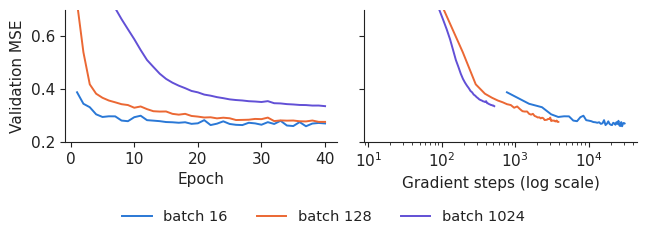

In [3]:
import torch, torch.nn as nn
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from scipy import stats
torch.set_num_threads(1)
SEED = 20261108
ca = pd.read_csv(DATA + 'california_housing.csv')
feat = [c for c in ca.columns if c != 'MedHouseVal_100k_usd']
Xc = ca[feat].values.astype(np.float32); yc = ca['MedHouseVal_100k_usd'].values.astype(np.float32)
i_tr, i_te = train_test_split(np.arange(len(ca)), test_size=0.2, random_state=SEED)
i_tr, i_va = train_test_split(i_tr, test_size=0.25, random_state=SEED)
mu, sd = Xc[i_tr].mean(0), Xc[i_tr].std(0); Z = (Xc - mu) / sd
Xtr, Xva, Xte, ytr, yva, yte = Z[i_tr], Z[i_va], Z[i_te], yc[i_tr], yc[i_va], yc[i_te]
lin = LinearRegression().fit(Xtr, ytr)
mse_lin_val = float(np.mean((lin.predict(Xva) - yva) ** 2)); mse_lin_te = float(np.mean((lin.predict(Xte) - yte) ** 2))

def make_mlp(d, hidden=(64, 64), act=nn.ReLU):
    layers, k = [], d
    for h in hidden:
        layers += [nn.Linear(k, h), act()]; k = h
    return nn.Sequential(*layers, nn.Linear(k, 1))

def make_opt(name, params, lr):
    return {'sgd': lambda: torch.optim.SGD(params, lr=lr), 'momentum': lambda: torch.optim.SGD(params, lr=lr, momentum=0.9),
            'rmsprop': lambda: torch.optim.RMSprop(params, lr=lr, alpha=0.99), 'adam': lambda: torch.optim.Adam(params, lr=lr),
            'adamw': lambda: torch.optim.AdamW(params, lr=lr, weight_decay=1e-2)}[name]()

def run_reg(opt_name, lr, seed=0, epochs=60, bs=128, sched=None):
    torch.manual_seed(SEED + seed); rng = np.random.default_rng(SEED + seed)
    m = make_mlp(Xtr.shape[1]); opt = make_opt(opt_name, m.parameters(), lr)
    spe = int(np.ceil(len(Xtr) / bs)); total = epochs * spe
    sch = {'step': lambda: torch.optim.lr_scheduler.StepLR(opt, step_size=20 * spe, gamma=0.1),
           'cosine': lambda: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total),
           'onecycle': lambda: torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=total, pct_start=0.3)}.get(sched, lambda: None)()
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr).view(-1, 1); Xv, yv = torch.tensor(Xva), torch.tensor(yva).view(-1, 1)
    val, lrs = [], []
    for ep in range(epochs):
        m.train(); idx = rng.permutation(len(Xt))
        for i in range(0, len(idx), bs):
            b = idx[i:i + bs]; opt.zero_grad(); nn.MSELoss()(m(Xt[b]), yt[b]).backward(); opt.step()
            lrs.append(opt.param_groups[0]['lr'])
            if sch is not None:
                sch.step()
        m.eval()
        with torch.no_grad():
            v = float(nn.MSELoss()(m(Xv), yv)); val.append(v if np.isfinite(v) else 1e9)
    with torch.no_grad():
        te = float(nn.MSELoss()(m(torch.tensor(Xte)), torch.tensor(yte).view(-1, 1)))
    return {'val': val, 'test': te if np.isfinite(te) else 1e9, 'lr': lrs[::spe]}
fig, axs = plt.subplots(1, 2, figsize=(6.6, 2.5), sharey=True)
for b, c in zip((16, 128, 1024), (PAL['data'], PAL['model'], '#6250d6')):
    v = np.array(run_reg('adam', 1e-3, seed=0, epochs=40, bs=b)['val']); spe = int(np.ceil(len(Xtr) / b))
    show(f'batch.{b}.val_ep5', f'batch {b}: validation MSE after 5 epochs', round(float(v[4]), 3))
    axs[0].plot(np.arange(1, 41), v, color=c, label=f'batch {b}'); axs[1].plot(np.arange(1, 41) * spe, v, color=c)
axs[1].set_xscale('log'); axs[0].set_ylim(0.2, 0.7); axs[0].set_xlabel('Epoch'); axs[1].set_xlabel('Gradient steps (log scale)'); axs[0].set_ylabel('Validation MSE')
legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('batch_size.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()